# Supervised Learning with the Support Vector Machine (SVM) Algorithm

This notebook implements Support Vector Machine (SVM) classification on `air_quality_dataset.csv` to enable a direct comparison with k-Nearest Neighbors (kNN), explore kernel behavior, visualize 2D decision boundaries, tune regularization ($C$), and summarize findings for the group presentation.


## Group Members
1. Rafid Islam
2. Sadia Sanji
3. Esuabious Jacob

## Task 1 - Use the Same Dataset and Apply SVM

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

df = pd.read_csv('air_quality_dataset.csv')

def categorize_aqi(pm25):
    if pm25 <= 35:
        return 'Good'
    elif pm25 <= 75:
        return 'Moderate'
    else:
        return 'Poor'

df['Air_Quality_Class'] = df['PM2.5'].apply(categorize_aqi)
print(f"Dataset Shape: {df.shape}")
print("\nClass Distribution:\n", df['Air_Quality_Class'].value_counts())

X = df.drop(columns=['Air_Quality_Class'])
y = df['Air_Quality_Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn_ref = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
knn_ref.fit(X_train_scaled, y_train)
knn_acc = accuracy_score(y_test, knn_ref.predict(X_test_scaled))
print(f"\nAssignment 1 kNN Baseline Accuracy (k=5): {knn_acc:.4f}")

svm_linear = SVC(kernel='linear', C=1.0, random_state=42)
svm_linear.fit(X_train_scaled, y_train)
y_pred_linear = svm_linear.predict(X_test_scaled)

print(f"Assignment 2 Base SVM Accuracy (Linear, C=1.0): {accuracy_score(y_test, y_pred_linear):.4f}")
print("\nClassification Report (Linear SVM):\n", classification_report(y_test, y_pred_linear))

Dataset Shape: (500, 11)

Class Distribution:
 Air_Quality_Class
Moderate    285
Poor        115
Good        100
Name: count, dtype: int64

Assignment 1 kNN Baseline Accuracy (k=5): 0.8500
Assignment 2 Base SVM Accuracy (Linear, C=1.0): 0.9300

Classification Report (Linear SVM):
               precision    recall  f1-score   support

        Good       0.91      1.00      0.95        20
    Moderate       0.96      0.91      0.94        57
        Poor       0.88      0.91      0.89        23

    accuracy                           0.93       100
   macro avg       0.92      0.94      0.93       100
weighted avg       0.93      0.93      0.93       100



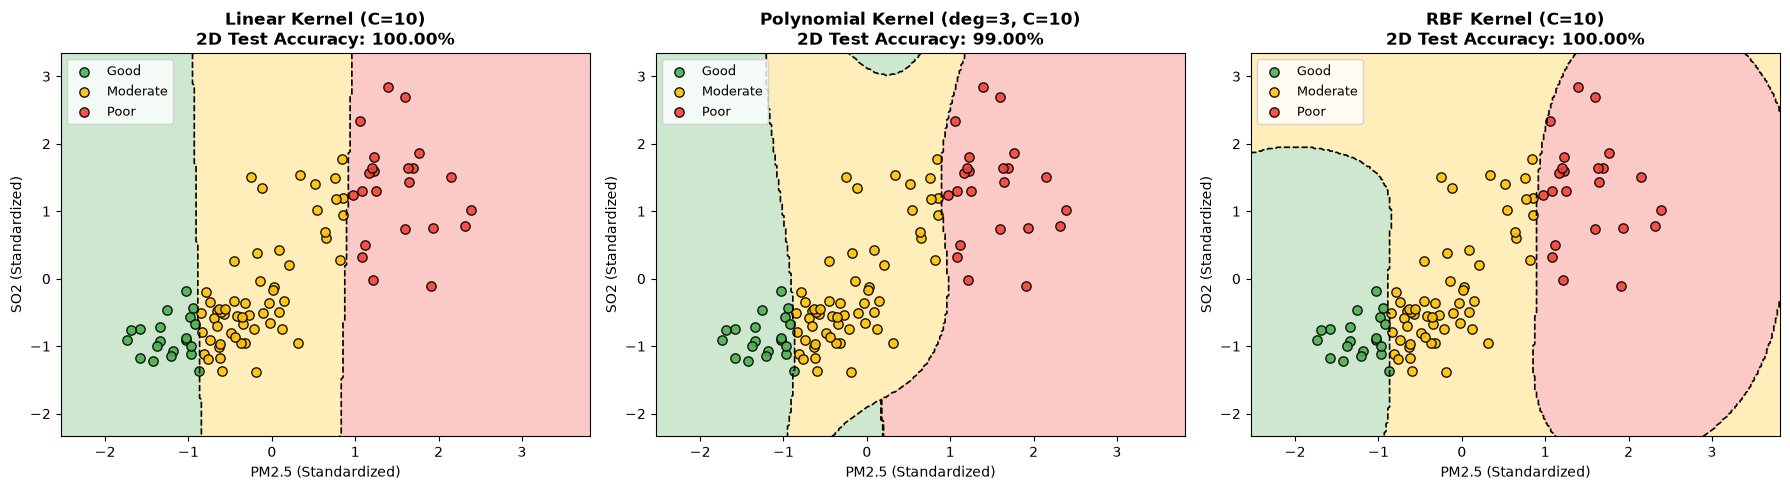

In [3]:
selected_features = ['PM2.5', 'SO2']
X_2d = df[selected_features]

le = LabelEncoder()
y_encoded = le.fit_transform(y)  
class_names = le.classes_

X_tr2, X_te2, y_tr2, y_te2 = train_test_split(
    X_2d, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
)

scaler_2d = StandardScaler()
X_tr2_s = scaler_2d.fit_transform(X_tr2)
X_te2_s = scaler_2d.transform(X_te2)

x_min, x_max = X_tr2_s[:, 0].min() - 0.6, X_tr2_s[:, 0].max() + 0.6
y_min, y_max = X_tr2_s[:, 1].min() - 0.6, X_tr2_s[:, 1].max() + 0.6
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
vis_kernels = [('linear', 'Linear Kernel (C=10)'), ('poly', 'Polynomial Kernel (deg=3, C=10)'), ('rbf', 'RBF Kernel (C=10)')]
colors = ['#4CAF50', '#FFC107', '#F44336'] 

for ax, (k_name, title) in zip(axes, vis_kernels):
    clf_2d = SVC(kernel=k_name, C=10.0, degree=3, random_state=42)
    clf_2d.fit(X_tr2_s, y_tr2)
    acc_2d = accuracy_score(y_te2, clf_2d.predict(X_te2_s))
    
    Z = clf_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.28, levels=[-0.5, 0.5, 1.5, 2.5], colors=colors)
    ax.contour(xx, yy, Z, levels=[0.5, 1.5], colors='black', linewidths=1.2, linestyles='--')
    
    for idx, cls_label in enumerate(class_names):
        mask = (y_te2 == idx)
        ax.scatter(
            X_te2_s[mask, 0], X_te2_s[mask, 1],
            c=colors[idx], label=cls_label, edgecolors='k', s=45, alpha=0.9
        )
    ax.set_title(f"{title}\n2D Test Accuracy: {acc_2d:.2%}", fontsize=12, fontweight='bold')
    ax.set_xlabel(f"{selected_features[0]} (Standardized)", fontsize=10)
    ax.set_ylabel(f"{selected_features[1]} (Standardized)", fontsize=10)
    ax.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.savefig('svm_decision_boundaries.png', dpi=300, bbox_inches='tight')
plt.show()

## Task 2 - Identify Real-World SVM Applications

## Task 3 - Parameter Tuning (Regularization Parameter $C$)

--- TASK 3: HYPERPARAMETER TUNING (C VALUES) ---
Kernel       C  Train Accuracy  Test Accuracy  Support Vectors
linear    0.01          0.6975           0.66              282
linear    0.10          0.9200           0.91              221
linear    1.00          0.9650           0.93              122
linear   10.00          0.9875           0.97               69
linear  100.00          0.9925           0.97               37
linear 1000.00          1.0000           0.99               29
  poly    0.01          0.6550           0.67              334
  poly    0.10          0.7550           0.73              286
  poly    1.00          0.8750           0.86              230
  poly   10.00          0.9550           0.87              163
  poly  100.00          0.9950           0.89              124
  poly 1000.00          1.0000           0.88              115
   rbf    0.01          0.5700           0.57              326
   rbf    0.10          0.7050           0.66              300
   rbf

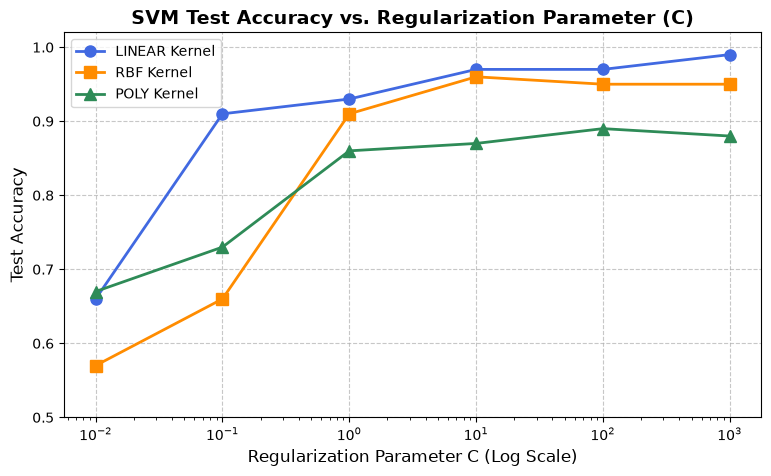

In [5]:
print("--- TASK 3: HYPERPARAMETER TUNING (C VALUES) ---")
c_values = [0.01, 0.1, 1, 10, 100, 1000]
tuning_records = []

for k in ['linear', 'poly', 'rbf']:
    for c in c_values:
        clf = SVC(kernel=k, C=c, degree=3, random_state=42)
        clf.fit(X_train_scaled, y_train)
        tr_acc = accuracy_score(y_train, clf.predict(X_train_scaled))
        te_acc = accuracy_score(y_test, clf.predict(X_test_scaled))
        n_sv = int(clf.n_support_.sum())
        tuning_records.append({
            'Kernel': k,
            'C': c,
            'Train Accuracy': round(tr_acc, 4),
            'Test Accuracy': round(te_acc, 4),
            'Support Vectors': n_sv
        })

tuning_df = pd.DataFrame(tuning_records)
print(tuning_df.to_string(index=False))

plt.figure(figsize=(9, 5))
for k, marker, color in [('linear', 'o', 'royalblue'), ('rbf', 's', 'darkorange'), ('poly', '^', 'seagreen')]:
    subset = tuning_df[tuning_df['Kernel'] == k]
    plt.plot(subset['C'], subset['Test Accuracy'], marker=marker, label=f'{k.upper()} Kernel', linewidth=2, markersize=8, color=color)

plt.xscale('log')
plt.title('SVM Test Accuracy vs. Regularization Parameter (C)', fontsize=14, fontweight='bold')
plt.xlabel('Regularization Parameter C (Log Scale)', fontsize=12)
plt.ylabel('Test Accuracy', fontsize=12)
plt.ylim(0.50, 1.02)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.savefig('svm_c_tuning.png', dpi=300, bbox_inches='tight')
plt.show()

## Task 4 - Kernel Performance Comparison

--- TASK 4: KERNEL PERFORMANCE COMPARISON ---
 Kernel  Train Accuracy (C=1)  Test Accuracy (C=1)  Avg Train Time (ms)  Support Vectors
 linear                0.9650                 0.93                5.984              122
   poly                0.8750                 0.86                4.352              230
    rbf                0.9300                 0.91                5.335              241
sigmoid                0.8525                 0.81                4.840              236


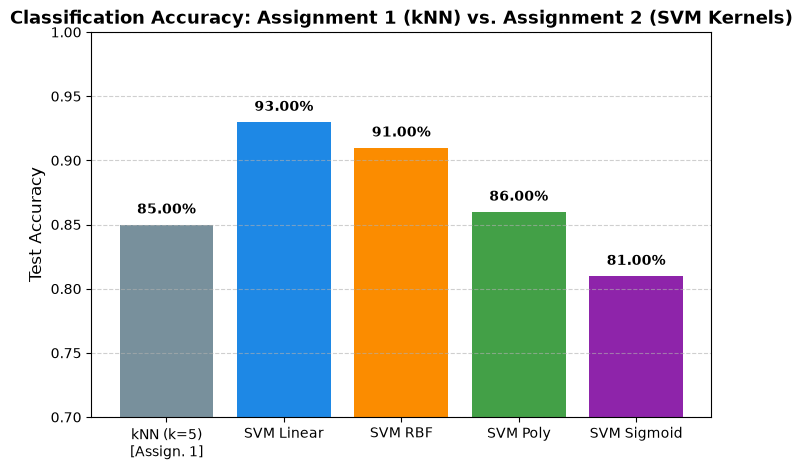

In [7]:
print("--- TASK 4: KERNEL PERFORMANCE COMPARISON ---")
kernels = ['linear', 'poly', 'rbf', 'sigmoid']
comparison_rows = []

for k in kernels:
    start = time.perf_counter()
    for _ in range(20):
        clf = SVC(kernel=k, C=1.0, degree=3, random_state=42)
        clf.fit(X_train_scaled, y_train)
    avg_train_ms = ((time.perf_counter() - start) / 20) * 1000
    
    train_acc = accuracy_score(y_train, clf.predict(X_train_scaled))
    test_acc = accuracy_score(y_test, clf.predict(X_test_scaled))
    
    comparison_rows.append({
        'Kernel': k,
        'Train Accuracy (C=1)': round(train_acc, 4),
        'Test Accuracy (C=1)': round(test_acc, 4),
        'Avg Train Time (ms)': round(avg_train_ms, 3),
        'Support Vectors': int(clf.n_support_.sum())
    })

comp_df = pd.DataFrame(comparison_rows)
print(comp_df.to_string(index=False))

plt.figure(figsize=(8, 5))
labels = ['kNN (k=5)\n[Assign. 1]', 'SVM Linear', 'SVM RBF', 'SVM Poly', 'SVM Sigmoid']
scores = [
    knn_acc,
    comp_df.loc[comp_df['Kernel'] == 'linear', 'Test Accuracy (C=1)'].values[0],
    comp_df.loc[comp_df['Kernel'] == 'rbf', 'Test Accuracy (C=1)'].values[0],
    comp_df.loc[comp_df['Kernel'] == 'poly', 'Test Accuracy (C=1)'].values[0],
    comp_df.loc[comp_df['Kernel'] == 'sigmoid', 'Test Accuracy (C=1)'].values[0]
]
bar_colors = ['#78909C', '#1E88E5', '#FB8C00', '#43A047', '#8E24AA']

bars = plt.bar(labels, scores, color=bar_colors)
plt.title('Classification Accuracy: Assignment 1 (kNN) vs. Assignment 2 (SVM Kernels)', fontsize=13, fontweight='bold')
plt.ylabel('Test Accuracy', fontsize=12)
plt.ylim(0.70, 1.00)
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, h + 0.006, f"{h:.2%}", ha='center', va='bottom', fontweight='bold')

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.savefig('svm_kernel_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## Task 5 - Group Discussion and Summary